# PyTorch VGG16 遷移學習（貓狗分類）

課程中（2025/11）用 PyTorch 完成了載入 VGG16、凍結特徵層、替換分類層、建立 DataLoader，但當時沒有接上訓練迴圈。2026/10 補上訓練、驗證與預測，並使用和 notebook 01 相同的資料（訓練 60 張、驗證 61 張），方便和 Keras 版的 VGG16（驗證準確率 78.7%）比較。

> 在 Colab 執行前，先到「執行階段 → 變更執行階段類型」選 **T4 GPU**。

## 0. 掛載雲端硬碟、設定路徑

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# 和 notebook 01 相同的資料夾：底下有 train/、validation/、test/
BASE_DATA_DIR = '/content/drive/MyDrive/[0]2025深度學習/1104/data'

Mounted at /content/drive


In [ ]:
import os, glob, random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from PIL import Image
import matplotlib.pyplot as plt

# 固定亂數種子，讓結果可以重現
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# 設定裝置 (GPU or CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("使用裝置：", device)

使用裝置： cuda


## 1. 資料轉換與 DataLoader

VGG16 預設輸入是 224×224，並且要用 ImageNet 的平均值和標準差做標準化，因為預訓練權重是在這個分布上學出來的。

In [ ]:
data_transform = transforms.Compose([
    transforms.Resize((224, 224)),                     # 調整圖片大小
    transforms.ToTensor(),                             # 轉為 Tensor，範圍 [0, 1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406],   # ImageNet 標準化
                         std=[0.229, 0.224, 0.225]),
])

train_dataset = datasets.ImageFolder(os.path.join(BASE_DATA_DIR, 'train'), transform=data_transform)
val_dataset   = datasets.ImageFolder(os.path.join(BASE_DATA_DIR, 'validation'), transform=data_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)  # 訓練時打亂
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)  # 驗證不需打亂

class_names = train_dataset.classes
print("類別：", class_names)
print(f"訓練 {len(train_dataset)} 張，驗證 {len(val_dataset)} 張")

類別： ['cat', 'dog']
訓練 60 張，驗證 61 張


## 2. 載入預訓練的 VGG16，凍結權重、替換分類層

- `weights=VGG16_Weights.DEFAULT` 是新版 torchvision 的寫法，取代已棄用的 `pretrained=True`。
- 先把所有參數設成不更新，再把最後一層（`classifier[6]`，原本輸出 1000 類）換成輸出 2 類的新層。新建立的層預設會更新，所以只有它會被訓練，和 Keras 版只訓練新分類層的設定一致。

In [ ]:
model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

num_features = model.classifier[6].in_features          # 4096
model.classifier[6] = nn.Linear(num_features, len(class_names))
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"可訓練參數 {trainable:,} / 全部 {total:,}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 142MB/s]


可訓練參數 8,194 / 全部 134,268,738


## 3. 訓練與驗證

- `model.train()`：啟用 Dropout（VGG16 的分類器裡有兩層 Dropout）
- `model.eval()` 加 `torch.no_grad()`：關閉 Dropout、不計算梯度，只做評估
- 只把需要更新的參數交給 optimizer；學習率 1e-4 和 Keras 版相同

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            count += images.size(0)
    return total_loss / count, correct / count

EPOCHS = 10
history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
        history[k].append(v)
    print(f"Epoch {epoch:2d}/{EPOCHS} - accuracy: {tr_acc:.4f} - loss: {tr_loss:.4f} "
          f"- val_accuracy: {va_acc:.4f} - val_loss: {va_loss:.4f}")

Epoch  1/10 - accuracy: 0.5000 - loss: 0.7538 - val_accuracy: 0.6721 - val_loss: 0.6360
Epoch  2/10 - accuracy: 0.5667 - loss: 0.6857 - val_accuracy: 0.8033 - val_loss: 0.5826
Epoch  3/10 - accuracy: 0.6833 - loss: 0.6168 - val_accuracy: 0.8361 - val_loss: 0.5338
Epoch  4/10 - accuracy: 0.8500 - loss: 0.4978 - val_accuracy: 0.8852 - val_loss: 0.4905
Epoch  5/10 - accuracy: 0.8167 - loss: 0.5161 - val_accuracy: 0.8852 - val_loss: 0.4520
Epoch  6/10 - accuracy: 0.8000 - loss: 0.4623 - val_accuracy: 0.9180 - val_loss: 0.4174
Epoch  7/10 - accuracy: 0.9000 - loss: 0.4189 - val_accuracy: 0.9344 - val_loss: 0.3868
Epoch  8/10 - accuracy: 0.9167 - loss: 0.3772 - val_accuracy: 0.9508 - val_loss: 0.3600
Epoch  9/10 - accuracy: 0.9333 - loss: 0.3818 - val_accuracy: 0.9508 - val_loss: 0.3359
Epoch 10/10 - accuracy: 0.8833 - loss: 0.3679 - val_accuracy: 0.9508 - val_loss: 0.3147


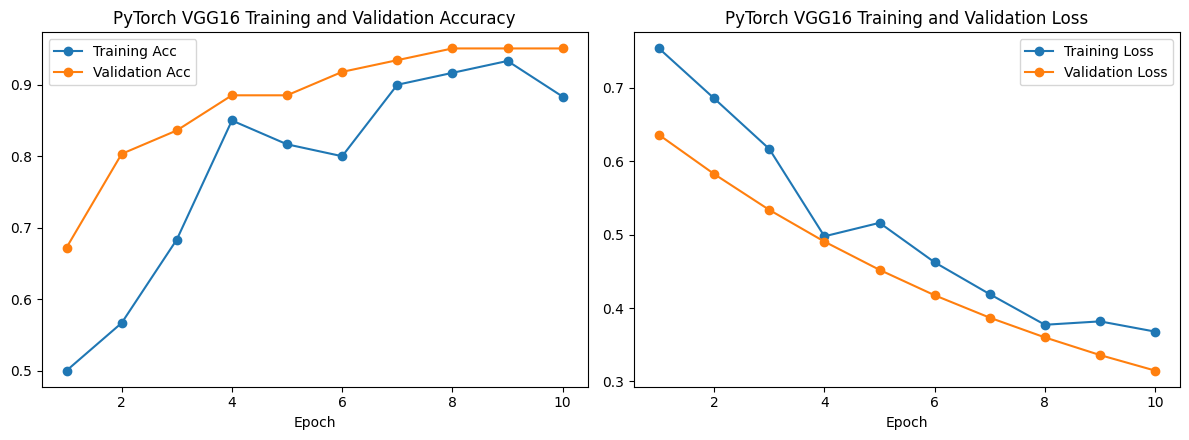

最後驗證準確率：95.1%（最佳 95.1%）


In [ ]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(epochs, history["accuracy"], "o-", label="Training Acc")
axes[0].plot(epochs, history["val_accuracy"], "o-", label="Validation Acc")
axes[0].set_title("PyTorch VGG16 Training and Validation Accuracy")
axes[1].plot(epochs, history["loss"], "o-", label="Training Loss")
axes[1].plot(epochs, history["val_loss"], "o-", label="Validation Loss")
axes[1].set_title("PyTorch VGG16 Training and Validation Loss")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

print(f"最後驗證準確率：{history['val_accuracy'][-1]*100:.1f}%（最佳 {max(history['val_accuracy'])*100:.1f}%）")

## 4. 預測沒看過的測試照片

In [8]:
test_files = sorted(f for ext in ("*.jpg", "*.jpeg", "*.png")
                    for f in glob.glob(os.path.join(glob.escape(BASE_DATA_DIR), "test", "**", ext), recursive=True))
print(f"找到 {len(test_files)} 張測試圖片")

model.eval()
with torch.no_grad():
    for path in test_files:
        image = data_transform(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
        probs = torch.softmax(model(image), dim=1)[0]
        idx = probs.argmax().item()
        print(f"--- 檔案: {os.path.basename(path)} ---")
        print(f"預測結果: {class_names[idx]} ({probs[idx].item()*100:.2f}%)")

找到 2 張測試圖片
--- 檔案: 157.jpg ---
預測結果: cat (66.79%)
--- 檔案: 159.jpg ---
預測結果: dog (77.98%)


## 5. 觀察

**結果：** 驗證準確率 95.1%（61 張答對 58 張），2 張測試照片都分類正確（貓 66.8%、狗 78.0%）。

**和 Keras 版 VGG16（78.7%）相比高很多，差別在分類層的設計，不是框架：**
- Keras 版用 `include_top=False`，丟掉 VGG16 原本的全連接層，換成 GlobalAveragePooling → Dense(256) → Dropout → Dense(1)。這些新層從零開始學，可訓練參數約 13 萬個，卻只有 60 張照片可以學。
- 這份 PyTorch 版保留 VGG16 在 ImageNet 上學好的兩層 4096 全連接層，只換掉最後一層，可訓練參數只有 8,194 個。
- 資料越少，能沿用的預訓練知識越多，效果越好。

**驗證準確率高，但預測信心偏低：** 測試照片的機率只有 67%–78%，Keras 版則接近 100%。這裡只訓練 10 個 epoch、學習率 1e-4，驗證 loss 到最後還在下降（0.31），輸出層還沒完全收斂，所以分得出類別，但機率還不夠「確定」。多訓練幾個 epoch 應該會改善。

**訓練準確率低於驗證準確率：** VGG16 分類器裡有兩層 Dropout，`model.train()` 時會隨機關掉神經元，`model.eval()` 時才全部使用。

**除錯紀錄：** 第一次執行時找到 0 張測試圖片。原因是資料夾名稱 `[0]2025深度學習` 的方括號被 `glob` 當成萬用字元（比對字元 0），改用 `glob.escape()` 後正常。